In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats
from scipy.stats import chisquare
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.api as sm

In [9]:
# The f_statistic value calculate
f_statistic = 1.38

df1 = 2  # Degrees of freedom for the numerator between groups
df2 = 6  # Degrees of freedom for denominator within groups

p_value = stats.f.sf(f_statistic, df1, df2)
print("P_value :", p_value)

P_value : 0.3213227185444337


## Python case study

In [10]:
df = pd.read_csv('train.csv').dropna(subset=['Age'])
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [11]:
model = ols('Age ~ Pclass', data=df).fit()
anova_result = sm.stats.anova_lm(model, type=2)
print(anova_result)

             df         sum_sq       mean_sq           F        PR(>F)
Pclass      1.0   20511.429755  20511.429755  112.386893  1.756699e-24
Residual  712.0  129945.206190    182.507312         NaN           NaN


## Post-hoc Test

In [12]:
for class1, class2 in [(1,2), (2,3), (3,1)]:
    print(class1, class2)
    print(stats.ttest_ind(df[df['Pclass'] == class1]['Age'], df[df['Pclass'] == class2]['Age']))

1 2
TtestResult(statistic=np.float64(5.485187676773201), pvalue=np.float64(7.835568991415144e-08), df=np.float64(357.0))
2 3
TtestResult(statistic=np.float64(3.927800191020872), pvalue=np.float64(9.715078600777851e-05), df=np.float64(526.0))
3 1
TtestResult(statistic=np.float64(-10.849122601201033), pvalue=np.float64(6.134470007830625e-25), df=np.float64(539.0))


In [14]:
tukey = pairwise_tukeyhsd(endog=df['Age'], groups=df['Pclass'], alpha=0.05)

,0,1,2,3,4,5,6
0,group1,group2,meandiff,p-adj,lower,upper,reject
1,1,2,-8.3558,0.0,-11.7041,-5.0075,True
2,1,3,-13.0928,0.0,-15.9622,-10.2234,True
3,2,3,-4.737,0.0005,-7.6763,-1.7977,True


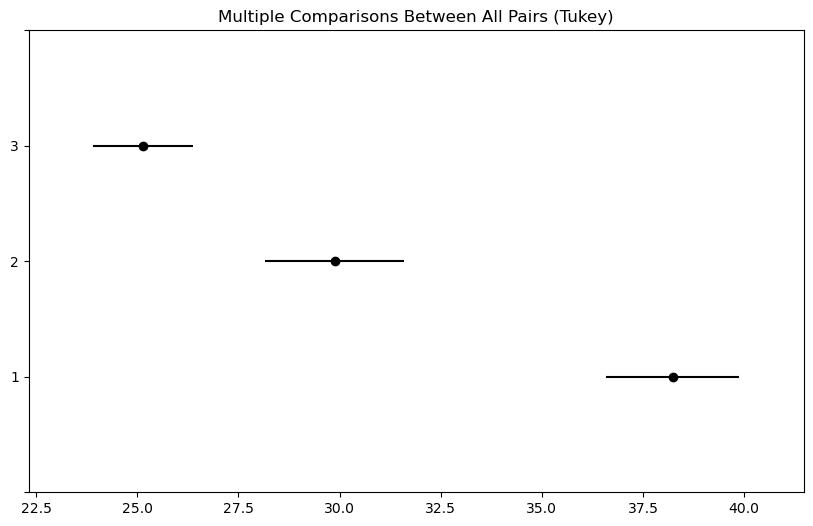

In [15]:
tukey.plot_simultaneous()
plt.vlines(x=49.57, ymin=0.5, ymax=4.5, color="red")
pd.DataFrame(tukey.summary())